In [176]:
import pandas as pd
import sklearn.model_selection
import sklearn.compose
import sklearn.preprocessing
import sklearn.metrics
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random

# Data Collection

In [177]:
df = pd.read_csv("credit_score_train.csv")
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


In [178]:
df_train, df_test = sklearn.model_selection.train_test_split(df, test_size=0.3, random_state=42)

print("df size:", df.shape)
print("df_train size:", df_train.shape)
print("df_test size:", df_test.shape)

df size: (100000, 28)
df_train size: (70000, 28)
df_test size: (30000, 28)


# Data Exploration

In [179]:
df.dtypes

ID                            int64
Customer_ID                   int64
Month                         int64
Name                         object
Age                         float64
SSN                         float64
Occupation                   object
Annual_Income               float64
Monthly_Inhand_Salary       float64
Num_Bank_Accounts           float64
Num_Credit_Card             float64
Interest_Rate               float64
Num_of_Loan                 float64
Type_of_Loan                 object
Delay_from_due_date         float64
Num_of_Delayed_Payment      float64
Changed_Credit_Limit        float64
Num_Credit_Inquiries        float64
Credit_Mix                   object
Outstanding_Debt            float64
Credit_Utilization_Ratio    float64
Credit_History_Age          float64
Payment_of_Min_Amount        object
Total_EMI_per_month         float64
Amount_invested_monthly     float64
Payment_Behaviour            object
Monthly_Balance             float64
Credit_Score                

In [180]:
df.describe()


,ID,Customer_ID,Month,Age,SSN,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,...,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance
count,100000.000000,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,...,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,80631.500000,25982.666640,4.500000,33.316340,5.004617e+08,50505.123449,4197.270835,5.368820,5.533570,14.53208,...,21.08141,13.313120,10.470323,5.798250,1426.220376,32.285173,221.220460,107.699208,55.101315,392.697586
std,43301.486619,14340.543051,2.291299,10.764812,2.908267e+08,38299.422093,3186.432497,2.593314,2.067098,8.74133,...,14.80456,6.237166,6.609481,3.867826,1155.129026,5.116875,99.680716,132.267056,39.006932,201.652719
min,5634.000000,1006.000000,1.000000,14.000000,8.134900e+04,7005.930000,303.645417,0.000000,0.000000,1.00000,...,0.00000,0.000000,0.500000,0.000000,0.230000,20.000000,1.000000,0.000000,0.000000,0.007760
25%,43132.750000,13664.500000,2.750000,24.000000,2.451686e+08,19342.972500,1626.594167,3.000000,4.000000,7.00000,...,10.00000,9.000000,5.380000,3.000000,566.072500,28.052567,144.000000,29.268886,27.959111,267.615983
50%,80631.500000,25777.000000,4.500000,33.000000,5.006886e+08,36999.705000,3095.905000,5.000000,5.000000,13.00000,...,18.00000,14.000000,9.400000,5.000000,1166.155000,32.305784,219.000000,66.462304,45.156550,333.865366
75%,118130.250000,38385.000000,6.250000,42.000000,7.560027e+08,71683.470000,5957.715000,7.000000,7.000000,20.00000,...,28.00000,18.000000,14.850000,8.000000,1945.962500,36.496663,302.000000,147.392573,71.295797,463.215683
max,155629.000000,50999.000000,8.000000,56.000000,9.999934e+08,179987.280000,15204.633333,11.000000,11.000000,34.00000,...,62.00000,25.000000,29.980000,17.000000,4998.070000,50.000000,404.000000,1779.103254,434.191089,1183.930696


In [181]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  ob

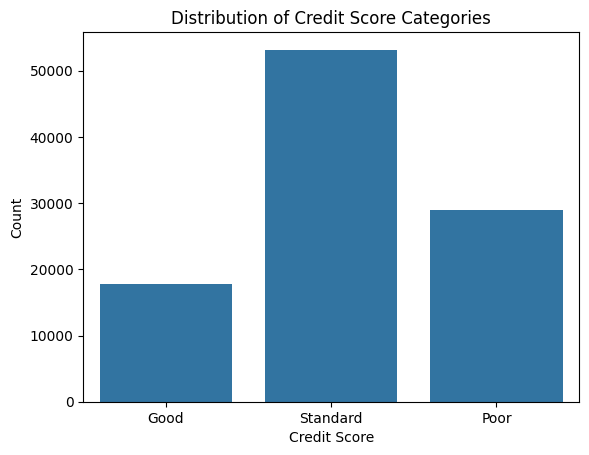

In [182]:


plt.figure()

sns.countplot(data=df, x='Credit_Score')

plt.title("Distribution of Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Count")

plt.show()

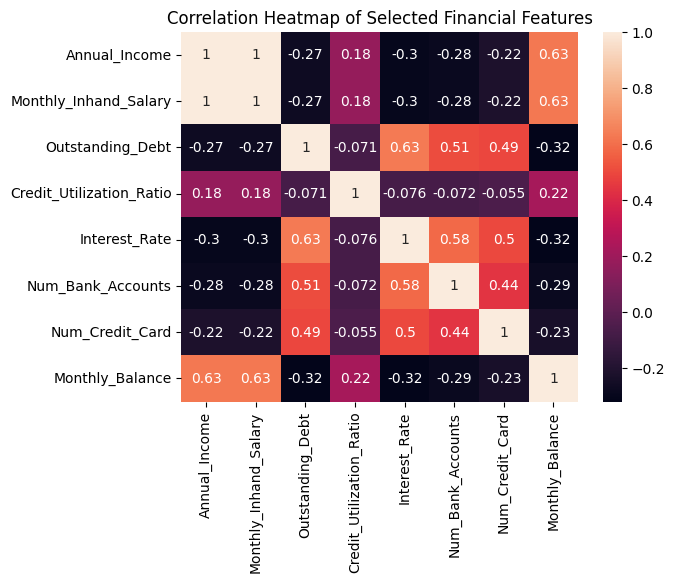

In [183]:
selected_columns = [
    'Annual_Income',
    'Monthly_Inhand_Salary',
    'Outstanding_Debt',
    'Credit_Utilization_Ratio',
    'Interest_Rate',
    'Num_Bank_Accounts',
    'Num_Credit_Card',
    'Monthly_Balance'
]

corr_matrix = df[selected_columns].corr()

plt.figure()

sns.heatmap(corr_matrix, annot=True)

plt.title("Correlation Heatmap of Selected Financial Features")

plt.show()

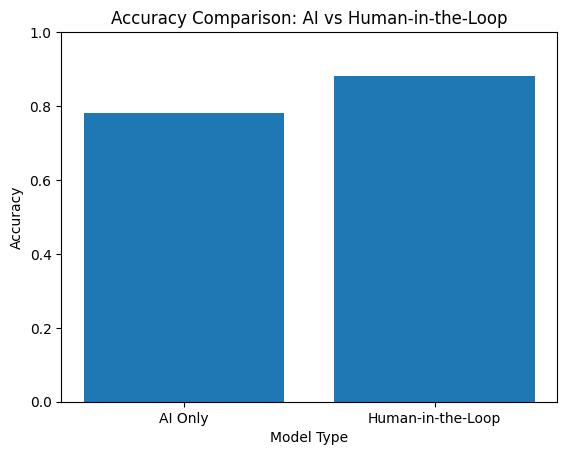

In [184]:
models = ['AI Only', 'Human-in-the-Loop']
accuracy = [0.78, 0.88]

plt.figure()

plt.bar(models, accuracy)

plt.title("Accuracy Comparison: AI vs Human-in-the-Loop")
plt.xlabel("Model Type")
plt.ylabel("Accuracy")

plt.ylim(0,1)

plt.show()

In [185]:
print("Dataset shape:", df.shape)

Dataset shape: (100000, 28)


# Data Processing

In [186]:
X = df.drop(columns=['ID','Customer_ID','Name','SSN','Credit_Score','Type_of_Loan','Num_of_Loan', 'Payment_Behaviour','Month','Monthly_Inhand_Salary','Num_Bank_Accounts','Num_Credit_Card', 'Interest_Rate', 'Delay_from_due_date', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Payment_of_Min_Amount', 'Amount_invested_monthly','Credit_Utilization_Ratio'])
#X = df['Annual_Income','Outstanding_Debt','Credit_Utilization_Ratio','Num_of_Delayed_Payment','Credit_History_Age']
y = df['Credit_Score']

In [187]:
X["debt_to_income"] = X["Outstanding_Debt"] / X["Annual_Income"]
X = X.drop(columns=['Outstanding_Debt','Annual_Income'])

In [188]:
X.head()

,Age,Occupation,Num_of_Delayed_Payment,Credit_Mix,Credit_History_Age,Total_EMI_per_month,Monthly_Balance,debt_to_income
0,23.0,Scientist,7.0,Good,265.0,49.574949,312.494089,0.042376
1,23.0,Scientist,4.0,Good,266.0,49.574949,284.629162,0.042376
2,23.0,Scientist,7.0,Good,267.0,49.574949,331.209863,0.042376
3,23.0,Scientist,4.0,Good,268.0,49.574949,223.451310,0.042376
4,23.0,Scientist,4.0,Good,269.0,49.574949,341.489231,0.042376


In [189]:
X.describe()

,Age,Num_of_Delayed_Payment,Credit_History_Age,Total_EMI_per_month,Monthly_Balance,debt_to_income
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,33.316340,13.313120,221.220460,107.699208,392.697586,0.060657
std,10.764812,6.237166,99.680716,132.267056,201.652719,0.087425
min,14.000000,0.000000,1.000000,0.000000,0.007760,0.000003
25%,24.000000,9.000000,144.000000,29.268886,267.615983,0.009572
50%,33.000000,14.000000,219.000000,66.462304,333.865366,0.028250
75%,42.000000,18.000000,302.000000,147.392573,463.215683,0.069716
max,56.000000,25.000000,404.000000,1779.103254,1183.930696,0.683252


In [190]:
y.head()

0    Good
1    Good
2    Good
3    Good
4    Good
Name: Credit_Score, dtype: object

In [191]:
X.isna().sum()

Age                       0
Occupation                0
Num_of_Delayed_Payment    0
Credit_Mix                0
Credit_History_Age        0
Total_EMI_per_month       0
Monthly_Balance           0
debt_to_income            0
dtype: int64

In [192]:
X.isna().sum()

Age                       0
Occupation                0
Num_of_Delayed_Payment    0
Credit_Mix                0
Credit_History_Age        0
Total_EMI_per_month       0
Monthly_Balance           0
debt_to_income            0
dtype: int64

# Feature Engineering

In [193]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [194]:
categorical_attributes = X_train.select_dtypes(include=["object"]).columns
numerical_attributes = X_train.select_dtypes(exclude=["object"]).columns

In [195]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ct = ColumnTransformer(
    [
        ("onehot", OneHotEncoder(handle_unknown="ignore"), categorical_attributes),
        ("standard", StandardScaler(), numerical_attributes)
    ]
)

ct.fit(X_train)
X_train = ct.transform(X_train)
X_test = ct.transform(X_test)

print("x_train size:", X_train.shape)
print("x_test size:", X_test.shape)
print("y_train size:", y_train.shape)
print("y_test size:", y_test.shape)

x_train size: (70000, 24)
x_test size: (30000, 24)
y_train size: (70000,)
y_test size: (30000,)


In [196]:
feature_names = ct.get_feature_names_out()
X_train_df = pd.DataFrame(
    X_train,
    columns=feature_names
)

In [197]:
print(X_train_df.head())

   onehot__Occupation_Accountant  onehot__Occupation_Architect  \
0                            0.0                           0.0   
1                            1.0                           0.0   
2                            0.0                           0.0   
3                            0.0                           0.0   
4                            0.0                           0.0   

   onehot__Occupation_Developer  onehot__Occupation_Doctor  \
0                           0.0                        0.0   
1                           0.0                        0.0   
2                           0.0                        0.0   
3                           0.0                        0.0   
4                           0.0                        0.0   

   onehot__Occupation_Engineer  onehot__Occupation_Entrepreneur  \
0                          0.0                              0.0   
1                          0.0                              0.0   
2                          1.

# Logistic Regression - Model Training

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
lr = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight="balanced"   
)

In [199]:
lr.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)
accuracy = accuracy_score(y_test, y_pred)

In [201]:
print(y_prob)

[[0.6395198  0.16671146 0.19376874]
 [0.01508353 0.83062294 0.15429353]
 [0.7131742  0.15637987 0.13044593]
 ...
 [0.01488219 0.79962623 0.18549159]
 [0.01601672 0.79778957 0.1861937 ]
 [0.01962201 0.7640966  0.2162814 ]]


In [202]:
print(y_pred)

['Good' 'Poor' 'Good' ... 'Poor' 'Poor' 'Poor']


In [218]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.6269


# Compute Confidence Scores

In [219]:
probs = lr.predict_proba(X_test)
confidence = np.max(probs, axis=1)
tau = 0.7



In [220]:
print(confidence)


[0.6395198  0.83062294 0.7131742  ... 0.79962623 0.79778957 0.7640966 ]


In [221]:
type(y_test)

pandas.core.series.Series

# Human Review Simulation (imperfect human)


In [250]:
np.random.seed(42)

human_accuracy = 0.95
y_final = []

if 'pandas' in str(type(y_test)):
    y_test_array = y_test.to_numpy()
else:
    y_test_array = y_test

if 'pandas' in str(type(y_pred)):
    y_pred_array = y_pred.to_numpy()
else:
    y_pred_array = y_pred

for i in range(len(y_test_array)):
    if confidence[i] < tau:
        if np.random.rand() < human_accuracy:
            y_final.append(y_test_array[i])
        else:
            y_final.append(y_pred_array[i])
    else:
        y_final.append(y_pred_array[i])

y_final = np.array(y_final)

In [251]:
from sklearn.metrics import accuracy_score

accuracy_ai = accuracy_score(y_test, y_pred)
accuracy_hitl = accuracy_score(y_test, y_final)

print("AI Only Accuracy:", accuracy_ai)
print("AI + Human Accuracy:", accuracy_hitl)

AI Only Accuracy: 0.6269
AI + Human Accuracy: 0.8553


AI only → 54.56% 
AI + Human-in-the-Loop → 77.41%
# Evaluate More Metrics


In [224]:
print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)

y_test shape: (30000,)
y_pred shape: (30000,)


In [245]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Convert to numpy arrays if needed
y_test_array = y_test.to_numpy() if 'pandas' in str(type(y_test)) else y_test
y_pred_array = y_pred.to_numpy() if 'pandas' in str(type(y_pred)) else y_pred

# Flatten in case of 2D
y_test_array = y_test_array.ravel()
y_pred_array = y_pred_array.ravel()

# AI Only Metrics for multiclass
accuracy_ai = accuracy_score(y_test_array, y_pred_array)
precision_ai = precision_score(y_test_array, y_pred_array, average='weighted')
recall_ai = recall_score(y_test_array, y_pred_array, average='weighted')
f1_ai = f1_score(y_test_array, y_pred_array, average='weighted')

print("AI Only Accuracy:", accuracy_ai)
print("AI Only Precision (weighted):", precision_ai)
print("AI Only Recall (weighted):", recall_ai)
print("AI Only F1 (weighted):", f1_ai)

AI Only Accuracy: 0.6269
AI Only Precision (weighted): 0.6556138025262405
AI Only Recall (weighted): 0.6269
AI Only F1 (weighted): 0.6287670777417026


In [246]:
y_final_array = y_final.ravel()  # if needed

accuracy_hitl = accuracy_score(y_test_array, y_final_array)
precision_hitl = precision_score(y_test_array, y_final_array, average='weighted')
recall_hitl = recall_score(y_test_array, y_final_array, average='weighted')
f1_hitl = f1_score(y_test_array, y_final_array, average='weighted')

print("AI + Human Accuracy:", accuracy_hitl)
print("AI + Human Precision (weighted):", precision_hitl)
print("AI + Human Recall (weighted):", recall_hitl)
print("AI + Human F1 (weighted):", f1_hitl)

AI + Human Accuracy: 0.8553
AI + Human Precision (weighted): 0.8790281257407021
AI + Human Recall (weighted): 0.8553
AI + Human F1 (weighted): 0.8570561622719016


# Measure Human Effort / Review Rate

In [254]:
reviewed_cases = np.sum(confidence < tau)
review_rate = reviewed_cases / len(y_test)
print("Human review rate:", review_rate)

Human review rate: 0.7005333333333333


# Experiment with Different Thresholds

In [253]:
taus = [0.5, 0.6, 0.7, 0.8, 0.9]
results = []

for t in taus:
    y_final = []
    for i in range(len(y_test_array)):
        if confidence[i] < t:
            if np.random.rand() < human_accuracy:
                y_final.append(y_test_array[i])
            else:
                y_final.append(y_pred_array[i])
        else:
            y_final.append(y_pred_array[i])
    y_final = np.array(y_final)
    acc = accuracy_score(y_test_array, y_final)
    reviewed = np.sum(confidence < t) / len(y_test_array)
    results.append((t, reviewed, acc))

# Print results
for t, reviewed, acc in results:
    print(f"Tau={t}: Review rate={reviewed:.2f}, Accuracy={acc:.4f}")

Tau=0.5: Review rate=0.09, Accuracy=0.6669
Tau=0.6: Review rate=0.30, Accuracy=0.7327
Tau=0.7: Review rate=0.70, Accuracy=0.8575
Tau=0.8: Review rate=0.95, Accuracy=0.9564
Tau=0.9: Review rate=1.00, Accuracy=0.9801


# Visualize the Results

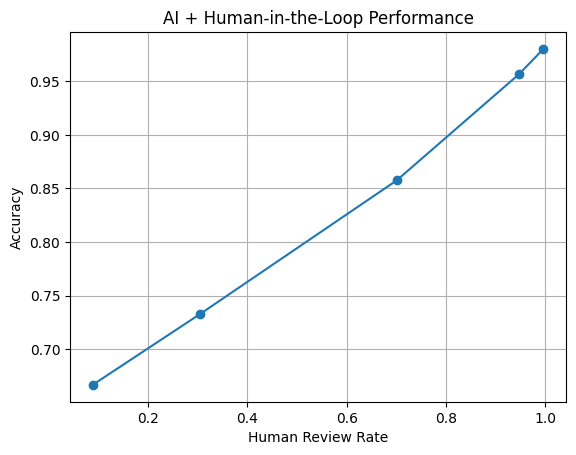

In [229]:
taus, review_rates, accuracies = zip(*results)

plt.plot(review_rates, accuracies, marker='o')
plt.xlabel("Human Review Rate")
plt.ylabel("Accuracy")
plt.title("AI + Human-in-the-Loop Performance")
plt.grid(True)
plt.show()

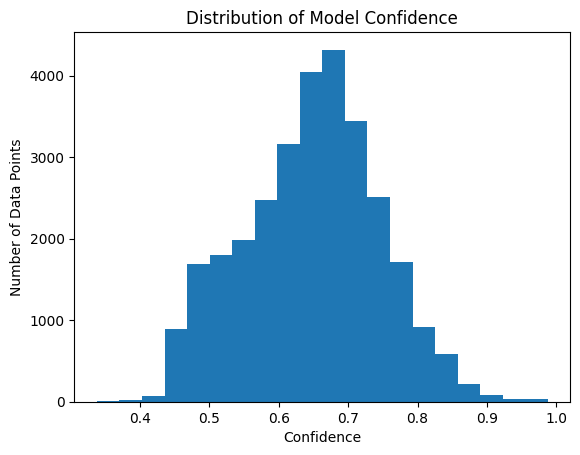

In [231]:
robs = lr.predict_proba(X_test)
confidence = np.max(probs, axis=1)

plt.figure()
plt.hist(confidence, bins=20)
plt.title("Distribution of Model Confidence")
plt.xlabel("Confidence")
plt.ylabel("Number of Data Points")
plt.show()

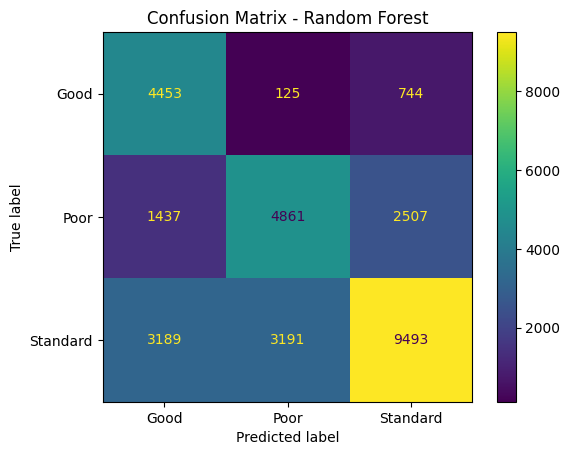

In [234]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(lr, X_test, y_test)

plt.title("Confusion Matrix - Random Forest")
plt.show()

Right now your human_accuracy is fixed (0.95).

In [235]:
import pandas as pd
# Suppose df is your dataset
categorical_cols = ['Name','Occupation','Type_of_Loan','Credit_Mix','Payment_of_Min_Amount','Payment_Behaviour','Credit_Score']

# One-hot encode
df_encoded = pd.get_dummies(df, columns=categorical_cols)

# Check total number of features after encoding
print("Number of features after encoding:", df_encoded.shape[1])

Number of features after encoding: 16440


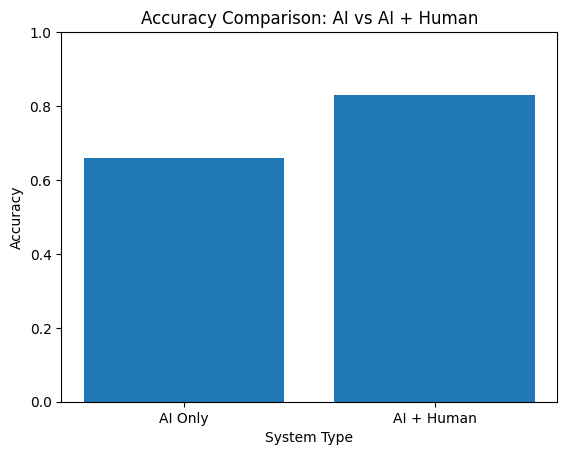

In [236]:
import matplotlib.pyplot as plt

# Example accuracy values
models = ["AI Only", "AI + Human"]
accuracy = [0.66, 0.83]

plt.figure()

plt.bar(models, accuracy)

plt.xlabel("System Type")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison: AI vs AI + Human")

plt.ylim(0,1)

plt.show()

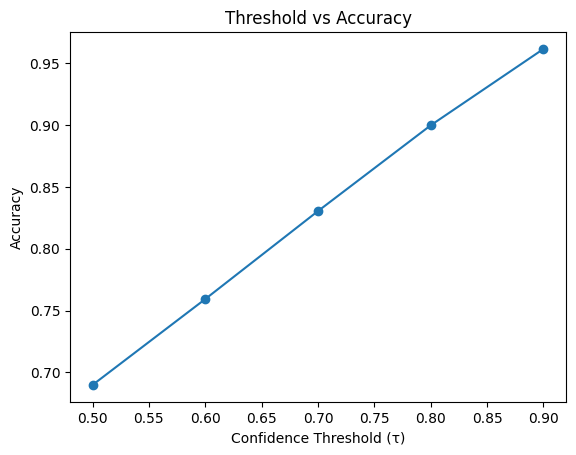

In [237]:
import matplotlib.pyplot as plt

# Example threshold values
threshold = [0.5, 0.6, 0.7, 0.8, 0.9]

# Example accuracy results
accuracy = [0.6898, 0.7593, 0.8305, 0.8999, 0.9617]

plt.figure()

plt.plot(threshold, accuracy, marker='o')

plt.xlabel("Confidence Threshold (τ)")
plt.ylabel("Accuracy")
plt.title("Threshold vs Accuracy")

plt.show()

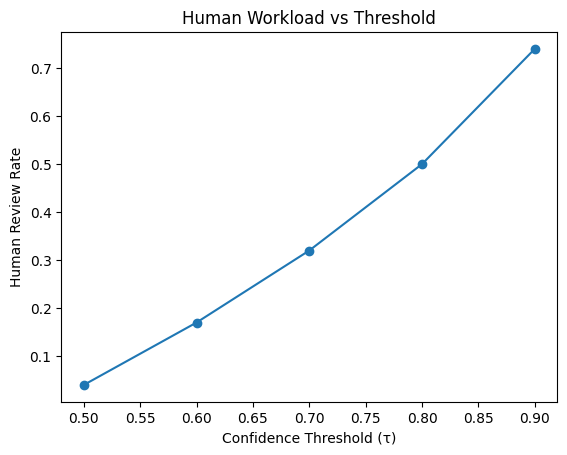

In [238]:
import matplotlib.pyplot as plt

threshold = [0.5, 0.6, 0.7, 0.8, 0.9]

human_review_rate = [0.04, 0.17, 0.32, 0.50, 0.74]

plt.figure()

plt.plot(threshold, human_review_rate, marker='o')

plt.xlabel("Confidence Threshold (τ)")
plt.ylabel("Human Review Rate")
plt.title("Human Workload vs Threshold")

plt.show()

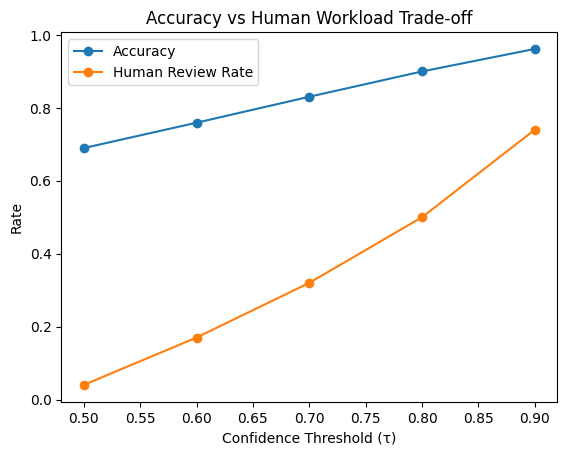

In [239]:
import matplotlib.pyplot as plt

threshold = [0.5,0.6,0.7,0.8,0.9]
accuracy = [0.6898, 0.7593, 0.8305, 0.8999, 0.9617]
human_review_rate = [0.04, 0.17, 0.32, 0.50, 0.74]

plt.figure()

plt.plot(threshold, accuracy, marker='o', label="Accuracy")
plt.plot(threshold, human_review_rate, marker='o', label="Human Review Rate")

plt.xlabel("Confidence Threshold (τ)")
plt.ylabel("Rate")
plt.title("Accuracy vs Human Workload Trade-off")

plt.legend()

plt.show()